In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch
torch.set_default_tensor_type(torch.DoubleTensor)
torch.set_default_dtype(torch.float64)

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem2
import problem3
import optimiser_problem2
from math import factorial
import pickle

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
order = 13
T = 2
Nt = 1_000

Wsig = problem3.BrownianSignatureFunctional(dim = 1, order = order, T = T, Nt = Nt)

In [3]:
np.random.seed(20250425)

W, W_sig_progression = Wsig.simulate_BM_sig(nsims=1)

In [4]:
with open('W_sig_1.pkl', 'rb') as f:
    expected_W_sig = pickle.load(f)
    f.close()

In [5]:
coef = np.sqrt(np.e)
dim = 2
nsim = 0

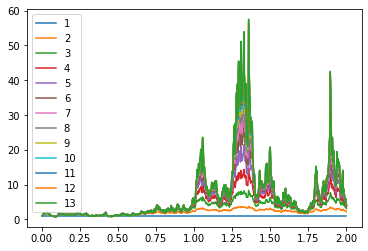

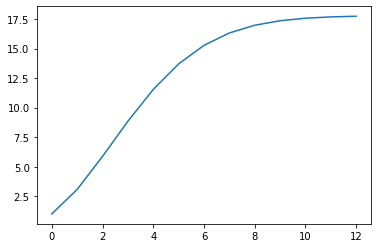

In [6]:
# growth c^N at level N

F_new = ta.Tensor(dim = 2, order = order)

F_new.value[0][()] = 1

W_sig_sample = [w[nsim] for w in W_sig_progression]
X_list = [np.zeros((Nt,)) for i in range(order)]

for i in range(order):
    F_new.value[i] = np.sqrt(((i+1)**(i+1)))*torch.ones([dim]*i)
    X = X_list[i]
    for t in range(Nt):
        X[t] = F_new.dot(W_sig_sample[t])
    X_list[i] = X
    plt.plot(Wsig.timesteps[1:], X, label = f'{i+1}')
    
plt.legend()
plt.show()

W_T_sig_convergence = np.array([X_list[i][3*Nt//4] for i in range(order)])
plt.plot(W_T_sig_convergence)
plt.show()